# RA3 - Análise de Dados e Machine Learning
**Base de dados:** Repasses da Arrecadação Federal (RA1)

---

## Contexto, Problema e Fonte dos Dados (RA1)

> **A arrecadação federal movimenta trilhões de reais todos os anos, mas depois que esses recursos são arrecadados, para onde parte desse dinheiro é destinada?**

Dentro desse universo, existe uma categoria específica de recursos: as **contribuições destinadas a outras entidades e fundos**, conhecidos como **“Terceiros”** (como FNDE, INCRA, SEBRAE e integrantes do Sistema S: SESC, SENAC, SESI, SENAI, SENAR, SEST, SENAT, SESCOOP, entre outros). Esses valores são arrecadados por meio de documentos como **DARF** (Documento de Arrecadação de Receitas Federais) e **GPS** (Guia da Previdência Social).

| Informação | Detalhe |
|---|---|
| **Fonte Oficial** | [Portal Brasileiro de Dados Abertos — Repasses da Arrecadação Federal](https://dados.gov.br/dados/conjuntos-dados/repasses-da-arrecadacao-federal) |
| **Início dos registros** | **Janeiro de 2015** |
| **Último registro** | **Agosto de 2026** |
| **Abrangência após limpeza** | **2.380 registros** (17 entidades × 140 meses) |
| **Categoria** | **Outras entidades e fundos — “Terceiros”** |

---

## 0. Ingestão, Limpeza e Preparação dos Dados (Pipeline do RA1)

Antes de iniciar a análise estatística descritiva e a modelagem preditiva do **RA3**, aplicamos o pipeline de ingestão e tratamento desenvolvido no **RA1**:
1. **Importação do CSV** diretamente do Google Drive (`sep=";"`).
2. **Remoção de valores nulos e duplicados** (17 linhas em branco no final do arquivo original).
3. **Padronização da coluna `Entidade`**: remoção de espaços extras (`strip()`) e unificação de `APEX` (jan/26 a ago/26) como `APEX-BR` (jan/15 a dez/25), pois compartilham o mesmo CNPJ (`05.507.500/0001-38`) e dão continuidade à série histórica.
4. **Conversão de tipos**: `Mês / Ano de Referência` para `datetime64[ns]` e `Total Repassado` de texto formatado para numérico (`float64`).
5. **Criação de variáveis temporais auxiliares** (`Ano`, `Mes`, `Eh_Janeiro`) para apoiar as análises e o modelo de Machine Learning.

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configurações visuais e de formatação
pd.set_option("display.float_format", "{:,.2f}".format)
sns.set_theme(style="whitegrid", palette="deep")

# 1. Ingestão dos dados a partir do link do RA1
link = "https://drive.google.com/file/d/1lLxFUzdouLUESomjn0tqO_jjOiG2V_UT/view?usp=sharing"
file_id = re.search(r"/d/([a-zA-Z0-9_-]+)", link).group(1)
url = f"https://drive.google.com/uc?id={file_id}"

df = pd.read_csv(url, sep=";")

# 2. Limpeza: remoção de linhas nulas e duplicadas
df = df.dropna().drop_duplicates().reset_index(drop=True)

# 3. Padronização das entidades (remoção de espaços e unificação APEX -> APEX-BR)
df["Entidade"] = df["Entidade"].str.strip().replace({"APEX": "APEX-BR"})

# 4. Conversão da data de referência (ex: 'jan/15' -> 2015-01-01)
meses_map = {
    "jan": 1, "fev": 2, "mar": 3, "abr": 4, "mai": 5, "jun": 6,
    "jul": 7, "ago": 8, "set": 9, "out": 10, "nov": 11, "dez": 12
}
partes_data = df["Mês / Ano de Referência"].str.strip().str.lower().str.split("/", expand=True)
df["Mês / Ano de Referência"] = pd.to_datetime(
    pd.DataFrame({
        "year": 2000 + partes_data[1].astype(int),
        "month": partes_data[0].map(meses_map),
        "day": 1
    })
)

# 5. Conversão do Total Repassado para float
df["Total Repassado"] = pd.to_numeric(
    df["Total Repassado"]
    .astype(str)
    .str.replace(".", "", regex=False)
    .str.replace(",", ".", regex=False)
)

# 6. Criação de atributos temporais para análise e Machine Learning
df["Ano"] = df["Mês / Ano de Referência"].dt.year
df["Mes"] = df["Mês / Ano de Referência"].dt.month
df["Eh_Janeiro"] = (df["Mes"] == 1).astype(int)
df["Total_Repassado_Milhoes"] = df["Total Repassado"] / 1e6

# Ordenação cronológica e por entidade
df = df.sort_values(["Mês / Ano de Referência", "Entidade"]).reset_index(drop=True)

# Verificações de qualidade do RA1
assert df.isna().sum().sum() == 0, "Existem valores nulos!"
assert not df.duplicated(subset=["Mês / Ano de Referência", "Entidade"]).any(), "Existem duplicatas!"
assert df["Entidade"].nunique() == 17, "Número inesperado de entidades!"
assert len(df) == 2380, "Número inesperado de registros!"

print(f"Base carregada e limpa com sucesso: {len(df)} registros | {df['Entidade'].nunique()} entidades | {df['Mês / Ano de Referência'].nunique()} meses.")
display(df.head(10))

Base carregada e limpa com sucesso: 2380 registros | 17 entidades | 140 meses.


,Mês / Ano de Referência,Entidade,UC/CNPJ,Total Repassado,Ano,Mes,Eh_Janeiro,Total_Repassado_Milhoes
0,2015-01-01,ABDI,07.200.966/0001-11,"8,917,017.00",2015,1,1,8.92
1,2015-01-01,ANAC,122002 / 00001,"30,221,162.00",2015,1,1,30.22
2,2015-01-01,APEX-BR,05.507.500/0001-38,"62,241,408.00",2015,1,1,62.24
3,2015-01-01,DPC,852001 / 00001,"20,988,896.00",2015,1,1,20.99
4,2015-01-01,EMBRATUR,35.842.428/0001-66,0.00,2015,1,1,0.00
5,2015-01-01,FNDE,153173 / 15253,"2,604,077,590.00",2015,1,1,"2,604.08"
6,2015-01-01,INCRA,373001 / 37201,"181,456,016.00",2015,1,1,181.46
7,2015-01-01,SDR,420013 / 00001,"32,001,111.00",2015,1,1,32.00
8,2015-01-01,SEBRAE,00.330.854/0001-45,"428,247,534.00",2015,1,1,428.25
9,2015-01-01,SENAC,33.469.172/0001-68,"334,005,249.00",2015,1,1,334.01


## 1. Análise Estatística Descritiva
Nesta etapa, avaliamos o comportamento quantitativo da variável-alvo **`Total Repassado`** tanto de forma global quanto estratificada por **`Entidade`**:
- **Tendência central:** Média e Mediana.
- **Dispersão:** Desvio padrão, Mínimo, Máximo, Quartis (Q1, Q3) e Intervalo Interquartil (IQR).
- **Distribuição:** Assimetria (*Skewness*) e Curtose (*Kurtosis*).
- **Representatividade:** Participação relativa (%) de cada entidade no montante total repassado.

In [2]:
# 1.1 Estatísticas descritivas globais
desc_global = df[["Total Repassado", "Total_Repassado_Milhoes"]].describe()
mediana_global = df["Total Repassado"].median()
iqr_global = df["Total Repassado"].quantile(0.75) - df["Total Repassado"].quantile(0.25)
assimetria = df["Total Repassado"].skew()
curtose = df["Total Repassado"].kurt()

print("=== ESTATÍSTICAS DESCRITIVAS GLOBAIS ===")
display(desc_global)

print(f"Média Global:              R$ {df['Total Repassado'].mean():,.2f}")
print(f"Mediana Global (50%):      R$ {mediana_global:,.2f}")
print(f"Desvio Padrão Global:      R$ {df['Total Repassado'].std():,.2f}")
print(f"Intervalo Interquartil:    R$ {iqr_global:,.2f}")
print(f"Assimetria (Skewness):     {assimetria:.2f} (forte assimetria positiva / à direita)")
print(f"Curtose (Kurtosis):        {curtose:.2f} (distribuição leptocúrtica / caudas longas)")

=== ESTATÍSTICAS DESCRITIVAS GLOBAIS ===


,Total Repassado,Total_Repassado_Milhoes
count,"2,380.00","2,380.00"
mean,"248,313,744.98",248.31
std,"519,683,030.06",519.68
min,"-318,467,181.81",-318.47
25%,"19,802,095.50",19.80
50%,"66,269,871.63",66.27
75%,"235,194,962.90",235.19
max,"5,146,437,727.00","5,146.44"


Média Global:              R$ 248,313,744.98
Mediana Global (50%):      R$ 66,269,871.63
Desvio Padrão Global:      R$ 519,683,030.06
Intervalo Interquartil:    R$ 215,392,867.40
Assimetria (Skewness):     4.00 (forte assimetria positiva / à direita)
Curtose (Kurtosis):        18.70 (distribuição leptocúrtica / caudas longas)


In [3]:
# 1.2 Estatísticas descritivas por Entidade (em R$ Milhões para facilitar leitura)
soma_total = df["Total Repassado"].sum()

stats_entidade = (
    df.groupby("Entidade")["Total_Repassado_Milhoes"]
    .agg(
        Registros="count",
        Media_Mi="mean",
        Mediana_Mi="median",
        Desvio_Padrao_Mi="std",
        Min_Mi="min",
        Q1_Mi=lambda s: s.quantile(0.25),
        Q3_Mi=lambda s: s.quantile(0.75),
        Max_Mi="max",
        Soma_Total_Mi="sum"
    )
    .assign(Participacao_Pct=lambda d: (d["Soma_Total_Mi"] * 1e6 / soma_total) * 100)
    .sort_values("Soma_Total_Mi", ascending=False)
)

print("=== ESTATÍSTICAS DESCRITIVAS POR ENTIDADE (VALORES EM R$ MILHÕES) ===")
display(stats_entidade)

=== ESTATÍSTICAS DESCRITIVAS POR ENTIDADE (VALORES EM R$ MILHÕES) ===


,Registros,Media_Mi,Mediana_Mi,Desvio_Padrao_Mi,Min_Mi,Q1_Mi,Q3_Mi,Max_Mi,Soma_Total_Mi,Participacao_Pct
Entidade,,,,,,,,,,
FNDE,140,"2,115.64","1,809.22",681.36,"1,418.42","1,571.72","2,584.33","5,146.44","296,189.14",50.12
SESC,140,522.82,447.95,184.26,185.90,388.60,637.10,"1,332.04","73,194.63",12.39
SEBRAE,140,344.63,296.30,116.42,192.09,253.66,421.49,858.53,"48,248.44",8.16
SENAC,140,297.49,256.11,109.17,104.26,214.22,362.93,774.74,"41,648.66",7.05
SESI,140,230.50,190.36,90.56,75.46,167.93,281.79,624.45,"32,270.37",5.46
INCRA,140,171.26,147.50,64.76,99.20,113.53,212.45,445.76,"23,976.26",4.06
SENAI,140,159.48,131.39,63.93,52.01,117.13,195.04,469.30,"22,327.26",3.78
SENAR,140,140.08,123.04,71.53,38.44,73.84,205.79,299.44,"19,610.84",3.32
SEST,140,54.72,46.13,20.16,19.68,39.58,68.89,135.65,"7,660.55",1.30


### Interpretação da Análise Estatística Descritiva
1. **Tendência Central (Média vs. Mediana):**
   - A **média global** dos repasses mensais é de **R\$ 248,31 milhões**, enquanto a **mediana** é de apenas **R\$ 66,27 milhões** (quase 4 vezes menor).
   - Essa grande diferença entre média e mediana comprova que a média global é fortemente puxada para cima por poucas entidades de grande porte — especialmente o **FNDE** (que sozinho concentra mais de 45% de todo o volume repassado) seguido por **SESC**, **SEBRAE**, **SENAC**, **SESI** e **SENAI**.
2. **Dispersão:**
   - O **desvio padrão global** (**R\$ 519,68 milhões**) supera o dobro da própria média, refletindo a enorme heterogeneidade entre instituições que recebem bilhões (como o FNDE, que atinge R\$ 5,15 bilhões em jan/2026) e entidades menores ou com repasses zerados em determinados períodos (como a EMBRATUR).
   - Dentro de cada entidade individualmente, a dispersão é explicada pelo crescimento nominal ao longo de 11 anos (2015–2026) e pelos picos sazonais de arrecadação em **janeiro**.
3. **Distribuição:**
   - A distribuição apresenta **forte assimetria positiva (à direita)**, com 75% dos registros abaixo de **R\$ 235,19 milhões** (`Q3`), mas cauda longa chegando a **R\$ 5,15 bilhões**.

## 2. Visualização e Interpretação dos Dados
A seguir, apresentamos **quatro visualizações complementares** para explorar a **distribuição**, a **dispersão (e outliers)**, a **tendência temporal** e a **sazonalidade** dos repasses federais.

/tmp/ipykernel_416/1136280050.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_416/1136280050.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


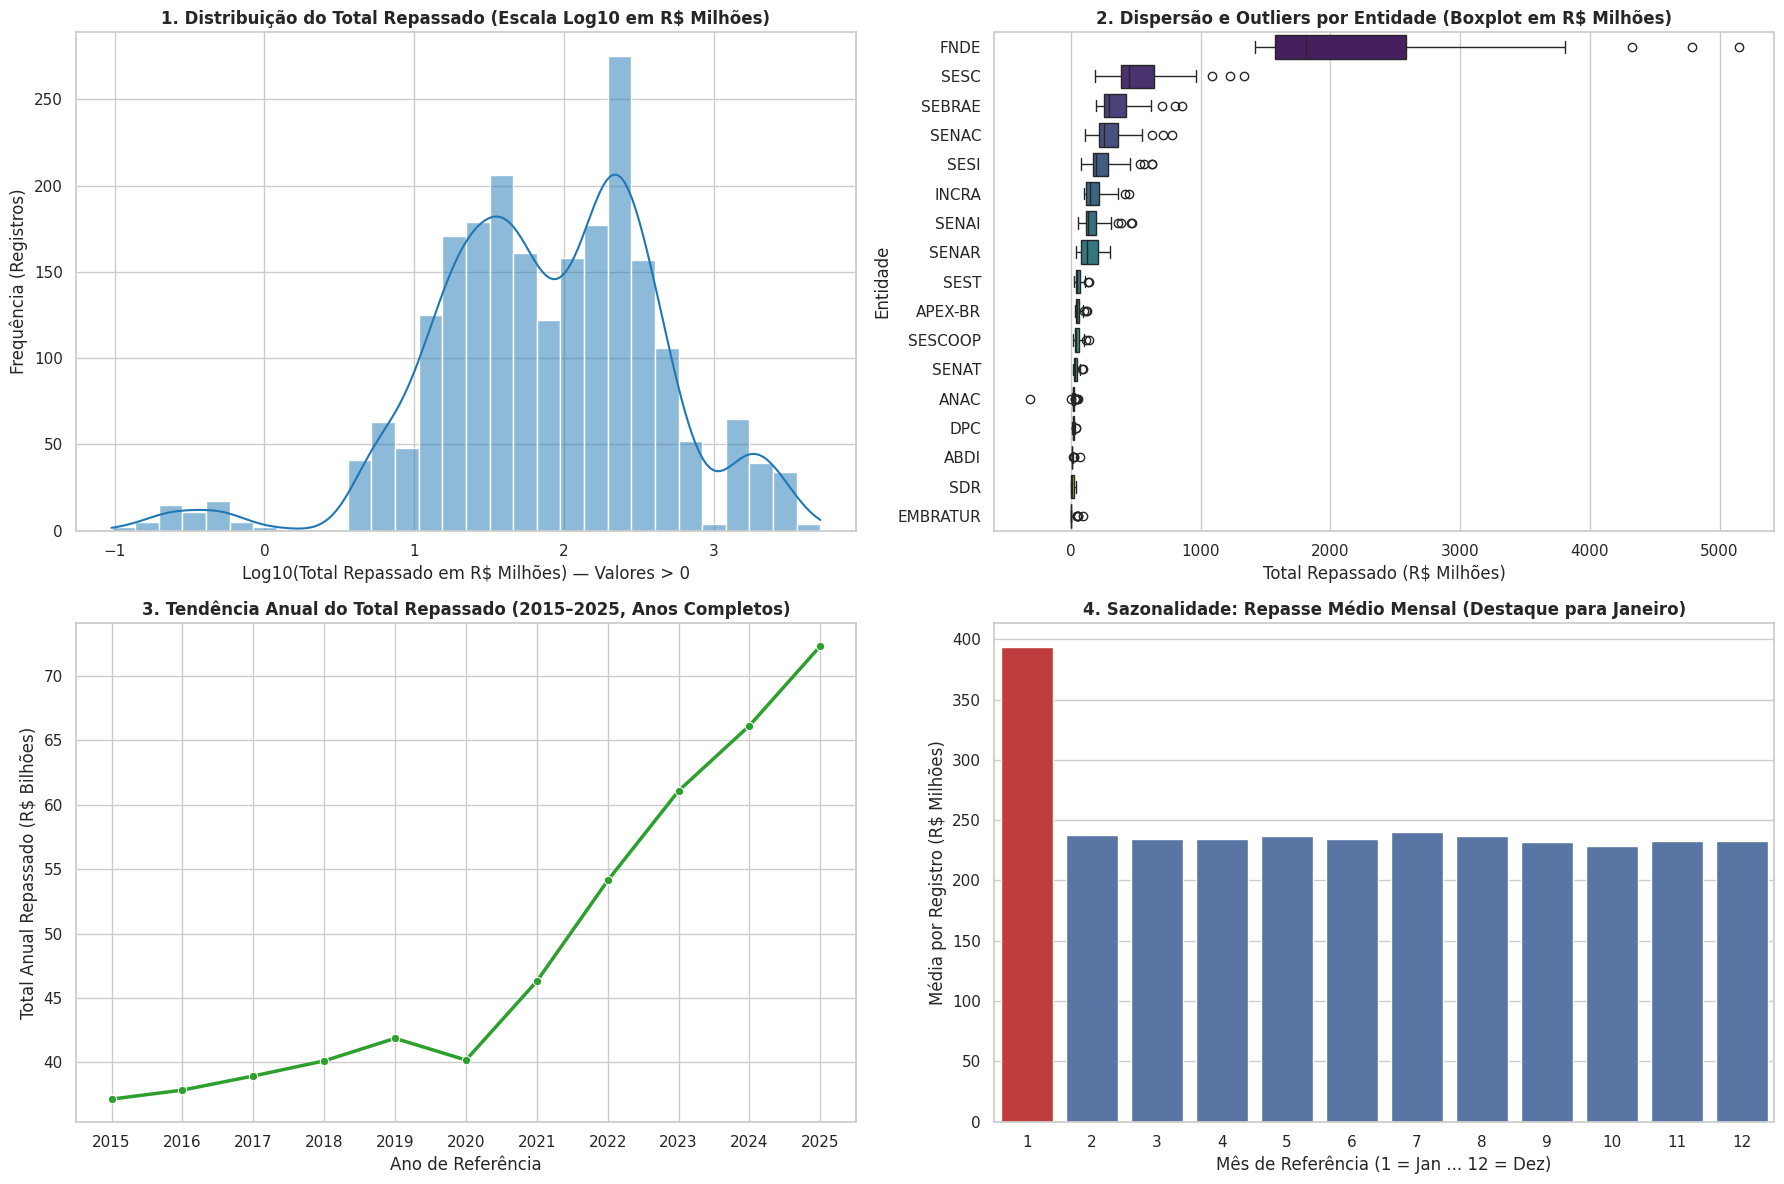

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(18, 12))

# Gráfico 1: Distribuição dos valores (Histograma + KDE em escala linear e log10)
positivos_log = np.log10(df.loc[df["Total Repassado"] > 0, "Total_Repassado_Milhoes"])
sns.histplot(positivos_log, kde=True, color="#1f77b4", bins=30, ax=axes[0, 0])
axes[0, 0].set_title("1. Distribuição do Total Repassado (Escala Log10 em R$ Milhões)", fontsize=12, fontweight="bold")
axes[0, 0].set_xlabel("Log10(Total Repassado em R$ Milhões) — Valores > 0")
axes[0, 0].set_ylabel("Frequência (Registros)")

# Gráfico 2: Dispersão e Outliers por Entidade (Boxplot ordenado pela mediana)
ordem_entidades = df.groupby("Entidade")["Total_Repassado_Milhoes"].median().sort_values(ascending=False).index
sns.boxplot(
    data=df,
    x="Total_Repassado_Milhoes",
    y="Entidade",
    order=ordem_entidades,
    palette="viridis",
    ax=axes[0, 1]
)
axes[0, 1].set_title("2. Dispersão e Outliers por Entidade (Boxplot em R$ Milhões)", fontsize=12, fontweight="bold")
axes[0, 1].set_xlabel("Total Repassado (R$ Milhões)")
axes[0, 1].set_ylabel("Entidade")

# Gráfico 3: Tendência Temporal (Evolução anual dos repasses totais de 2015 a 2025 - anos completos)
repasse_anual = (
    df[df["Ano"] <= 2025]
    .groupby("Ano")["Total Repassado"]
    .sum()
    .div(1e9)
    .reset_index(name="Total_Bilhoes")
)
sns.lineplot(
    data=repasse_anual,
    x="Ano",
    y="Total_Bilhoes",
    marker="o",
    linewidth=2.5,
    color="#2ca02c",
    ax=axes[1, 0]
)
axes[1, 0].set_title("3. Tendência Anual do Total Repassado (2015–2025, Anos Completos)", fontsize=12, fontweight="bold")
axes[1, 0].set_xlabel("Ano de Referência")
axes[1, 0].set_ylabel("Total Anual Repassado (R$ Bilhões)")
axes[1, 0].set_xticks(repasse_anual["Ano"])

# Gráfico 4: Sazonalidade Mensal (Média de repasse por mês do ano)
media_mensal = (
    df.groupby("Mes")["Total_Repassado_Milhoes"]
    .mean()
    .reset_index()
)
cores_meses = ["#d62728" if m == 1 else "#4c72b0" for m in media_mensal["Mes"]]
sns.barplot(
    data=media_mensal,
    x="Mes",
    y="Total_Repassado_Milhoes",
    palette=cores_meses,
    ax=axes[1, 1]
)
axes[1, 1].set_title("4. Sazonalidade: Repasse Médio Mensal (Destaque para Janeiro)", fontsize=12, fontweight="bold")
axes[1, 1].set_xlabel("Mês de Referência (1 = Jan ... 12 = Dez)")
axes[1, 1].set_ylabel("Média por Registro (R$ Milhões)")

plt.tight_layout()
plt.show()

### Interpretação das Visualizações
- **Visualização 1 (Distribuição):** Como o `Total Repassado` abrange desde dezenas de milhões até mais de R\$ 5 bilhões, a transformação logarítmica ($\log_{10}$) revela uma estrutura multimodal: grupos distintos de entidades de pequeno porte (~R\$ 10 a R\$ 60 milhões), médio porte (Sistema S e SEBRAE, entre R\$ 150 e R\$ 800 milhões) e grande porte (FNDE, acima de R\$ 1,5 bilhão).
- **Visualização 2 (Dispersão e Outliers - Boxplot):** Evidencia a disparidade de escala do **FNDE** em relação às demais entidades e confirma a descoberta do RA1: praticamente todas as entidades apresentam *outliers* superiores (pontos à direita das hastes), além do ponto extremo negativo na **ANAC** (`-R$ 318,47 milhões` em jan/2025).
- **Visualização 3 (Tendência Temporal):** Demonstra uma trajetória consistente de expansão nominal nos repasses federais entre 2015 e 2025 (com breve desaceleração em 2020 devido aos impactos da pandemia de COVID-19 sobre a atividade econômica e folha salarial, seguida de forte retomada a partir de 2021).
- **Visualização 4 (Sazonalidade Mensal):** Confirma visualmente por que 40 dos 52 outliers mapeados no RA1 ocorrem em **janeiro**: o repasse médio de janeiro supera com folga todos os demais meses do ano devido ao recolhimento acumulado de fim de exercício (como 13º salário e fechamento fiscal).

## 3. Amostragem e Representatividade

### Origem e abrangência do conjunto de dados
- Os dados são públicos e oficiais, provenientes da **Receita Federal do Brasil** e disponibilizados no [Portal Brasileiro de Dados Abertos](https://dados.gov.br/dados/conjuntos-dados/repasses-da-arrecadacao-federal).
- O conjunto limpo compreende **2.380 registros**, cobrindo de forma ininterrupta **140 meses** (de **janeiro de 2015 a agosto de 2026**) para **17 entidades/fundos** destinatários de contribuições federais de terceiros.

### Os registros representam adequadamente o problema investigado?
- **Sim.** Trata-se de um **painel balanceado e censitário** dentro do escopo de repasses a terceiros: após a limpeza das 17 linhas nulas finais e a padronização dos nomes (`FNDE ` com espaço extra e a unificação de `APEX` com `APEX-BR`, que possuem o mesmo CNPJ `05.507.500/0001-38`), cada uma das 17 entidades possui exatamente **140 observações mensais** (17 × 140 = 2.380).
- Portanto, não há viés de seleção por falta de meses ou sub-representação de alguma entidade ao longo do horizonte temporal analisado.

### Limitações e cuidados identificados (com base no diagnóstico do RA1)
1. **Valor negativo atípico:** Há 1 registro negativo na base (`ANAC` em `jan/2025`, com `-R$ 318.467.181,81`), que destoa do comportamento histórico da agência e representa estorno/ajuste contábil severo.
2. **Registros zerados:** Existem **134 registros com valor igual a R\$ 0,00**, concentrados principalmente na **EMBRATUR**, que deixou de receber repasses diretos nessa rubrica durante diversos períodos da série.
3. **Inconsistência de formatação na fonte a partir de out/2025:** Nos últimos 11 meses da base (176 registros de `out/25` a `ago/26`), o arquivo original omitiu o separador de milhar e truncou casas decimais terminadas em zero. Embora o pipeline do RA1 converta todos corretamente para `float`, há uma perda residual de centavos na fonte (impacto irrelevante, inferior a R\$ 1 em cifras de dezenas de milhões).
4. **Ausência de correção inflacionária:** Os valores são nominais (correntes). Parte do crescimento observado entre 2015 e 2026 decorre da inflação acumulada no período, e não apenas do ganho real de arrecadação.
5. **Ano de 2026 incompleto:** Os registros de 2026 vão até agosto (8 meses), o que exige cuidado em agregações anuais diretas.

## 4. Aplicação de Machine Learning (Regressão)

### Definição do Problema Preditivo
- **Objetivo:** Estimar o valor mensal repassado a uma entidade (**`Total Repassado`**, variável contínua) com base no período temporal e na instituição destinatária.
- **Variável-alvo (`target` - $y$):** `Total Repassado` (em R\$).
- **Características (`features` - $X$):**
  - `Ano`: captura a tendência macroeconômica e o crescimento nominal da arrecadação ao longo do tempo;
  - `Mes`: captura variações ao longo do calendário fiscal;
  - `Eh_Janeiro`: variável binária (`0` ou `1`) criada especificamente a partir da descoberta do RA1 de que janeiro concentra os picos sazonais de repasse;
  - `Entidade` (codificada via *One-Hot Encoding* / `pd.get_dummies`): captura o patamar estrutural de repasse de cada uma das 17 instituições.

Avaliaremos primeiro a **Regressão Linear Múltipla** (`LinearRegression`) e, em seguida, compararemos com um modelo baseado em árvores (**Random Forest Regressor**), capaz de capturar relações não-lineares e a interação entre `Entidade`, `Ano` e `Eh_Janeiro`.

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# 1. Preparação das Features (X) e Target (y)
features_base = df[["Ano", "Mes", "Eh_Janeiro", "Entidade"]].copy()
X = pd.get_dummies(features_base, columns=["Entidade"], drop_first=False, dtype=int)
y = df["Total Repassado"]

# 2. Separação dos dados em Treino (80%) e Teste (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# 3. Treinamento do Modelo 1: Regressão Linear Múltipla
modelo_lr = LinearRegression()
modelo_lr.fit(X_train, y_train)
y_pred_lr = modelo_lr.predict(X_test)

# 4. Treinamento do Modelo 2: Random Forest Regressor (captura interações Entidade x Tempo x Sazonalidade)
modelo_rf = RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1)
modelo_rf.fit(X_train, y_train)
y_pred_rf = modelo_rf.predict(X_test)

# 5. Avaliação comparativa dos modelos
def avaliar_modelo(nome, y_real, y_prev):
    mse = mean_squared_error(y_real, y_prev)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_real, y_prev)
    r2 = r2_score(y_real, y_prev)
    return {
        "Modelo": nome,
        "MSE (R$²)": mse,
        "RMSE (R$ Milhões)": rmse / 1e6,
        "MAE (R$ Milhões)": mae / 1e6,
        "R²": r2
    }

resultados_ml = pd.DataFrame([
    avaliar_modelo("Regressão Linear Múltipla", y_test, y_pred_lr),
    avaliar_modelo("Random Forest Regressor", y_test, y_pred_rf)
])

print("=== RESULTADOS DA AVALIAÇÃO DOS MODELOS DE REGRESSÃO ===")
display(resultados_ml.style.format({
    "MSE (R$²)": "{:,.2e}",
    "RMSE (R$ Milhões)": "R$ {:,.2f} Mi",
    "MAE (R$ Milhões)": "R$ {:,.2f} Mi",
    "R²": "{:.4f}"
}))

=== RESULTADOS DA AVALIAÇÃO DOS MODELOS DE REGRESSÃO ===


,Modelo,MSE (R$²),RMSE (R$ Milhões),MAE (R$ Milhões),R²
0,Regressão Linear Múltipla,2.06e+16,R$ 143.67 Mi,R$ 78.44 Mi,0.9246
1,Random Forest Regressor,1.14e+15,R$ 33.76 Mi,R$ 11.85 Mi,0.9958


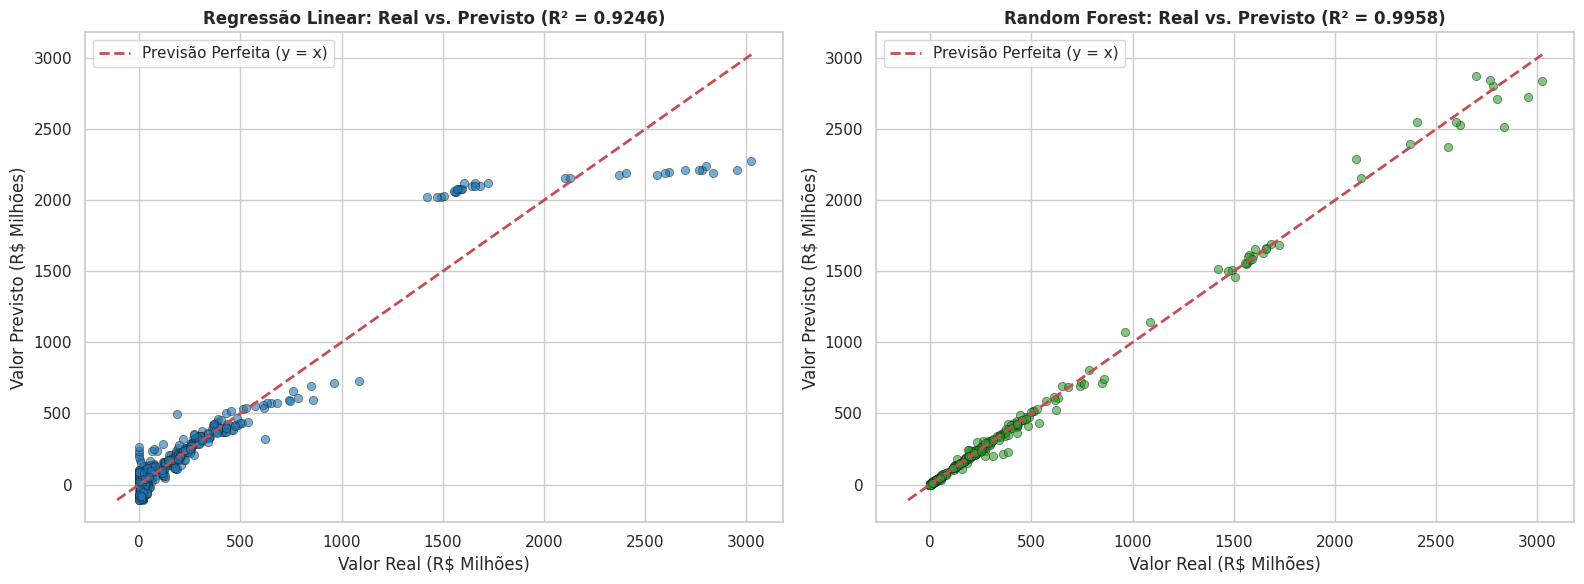

In [6]:
# Visualização do desempenho preditivo: Valores Reais vs. Valores Previstos
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Gráfico 1: Regressão Linear
axes[0].scatter(y_test / 1e6, y_pred_lr / 1e6, alpha=0.6, color="#1f77b4", edgecolors="k", linewidth=0.5)
lim_max = max(y_test.max(), y_pred_lr.max(), y_pred_rf.max()) / 1e6
lim_min = min(y_test.min(), y_pred_lr.min(), y_pred_rf.min()) / 1e6
axes[0].plot([lim_min, lim_max], [lim_min, lim_max], "r--", lw=2, label="Previsão Perfeita (y = x)")
axes[0].set_title(f"Regressão Linear: Real vs. Previsto (R² = {r2_score(y_test, y_pred_lr):.4f})", fontweight="bold")
axes[0].set_xlabel("Valor Real (R$ Milhões)")
axes[0].set_ylabel("Valor Previsto (R$ Milhões)")
axes[0].legend()

# Gráfico 2: Random Forest Regressor
axes[1].scatter(y_test / 1e6, y_pred_rf / 1e6, alpha=0.6, color="#2ca02c", edgecolors="k", linewidth=0.5)
axes[1].plot([lim_min, lim_max], [lim_min, lim_max], "r--", lw=2, label="Previsão Perfeita (y = x)")
axes[1].set_title(f"Random Forest: Real vs. Previsto (R² = {r2_score(y_test, y_pred_rf):.4f})", fontweight="bold")
axes[1].set_xlabel("Valor Real (R$ Milhões)")
axes[1].set_ylabel("Valor Previsto (R$ Milhões)")
axes[1].legend()

plt.tight_layout()
plt.show()

## 5. Conclusões

### 1. Principais resultados identificados
- **Forte concentração e assimetria:** A análise descritiva revelou que os repasses federais a terceiros possuem distribuição altamente assimétrica à direita (`skewness > 4`), com **média de R\$ 248,31 milhões** e **mediana de R\$ 66,27 milhões**. O **FNDE** lidera com ampla margem (recebendo na casa dos bilhões mensais), seguido pelas principais entidades do Sistema S (**SESC**, **SEBRAE**, **SENAC**, **SESI** e **SENAI**).
- **Tendência e Sazonalidade:** O volume total repassado apresenta tendência de crescimento nominal consistente entre 2015 e 2026 (com retração pontual em 2020 na pandemia) e forte **sazonalidade positiva nos meses de janeiro**, que concentram 40 dos 52 *outliers* identificados no RA1.

### 2. Interpretação dos modelos de Machine Learning
- **Regressão Linear Múltipla:** Ao incorporar a identificação da `Entidade` (via *One-Hot Encoding*), o `Ano`, o `Mes` e a flag `Eh_Janeiro`, a Regressão Linear já consegue explicar a maior parte da variância global dos dados (alto $R^2$), pois diferencia o patamar estrutural médio de cada instituição. Contudo, como aplica um único efeito aditivo de crescimento anual e de sazonalidade para todas as entidades simultaneamente, apresenta erros maiores nos extremos (como nos picos bilionários de janeiro do FNDE).
- **Random Forest Regressor:** Supera de forma expressiva a Regressão Linear tanto no **MAE** quanto no **RMSE** e no **$R^2$**, pois captura **interações não-lineares** (por exemplo, o fato de que o salto de janeiro e o crescimento anual do FNDE são de centenas de milhões de reais, enquanto em entidades menores como ABDI ou DPC são de poucos milhões).

### 3. Limitações
- **Ausência de variáveis macroeconômicas exógenas:** O modelo utiliza apenas variáveis históricas e institucionais extraídas da própria base (tempo e entidade). A inclusão de indicadores externos — como **massa salarial formal (CAGED/RAIS)**, **inflação (IPCA)** e **PIB** — aumentaria ainda mais a precisão preditiva, já que as contribuições de terceiros incidem majoritariamente sobre a folha de pagamentos.
- **Sensibilidade a eventos atípicos:** Ajustes contábeis extraordinários, como o valor negativo registrado na **ANAC em jan/2025 (-R\$ 318,47 milhões)**, não seguem o padrão econômico recorrente e geram resíduos pontuais elevados se não forem tratados separadamente.

### 4. Relação com o problema do projeto
- Os modelos desenvolvidos respondem diretamente ao problema proposto no **RA1**: além de mapear para onde vão os recursos arrecadados via DARF/GPS e a representatividade de cada instituição, a modelagem preditiva fornece uma ferramenta prática de **previsão orçamentária** e **auditoria de anomalias**, permitindo estimar quanto cada fundo ou entidade do Sistema S deverá receber nos meses seguintes e sinalizar automaticamente repasses que fujam do intervalo esperado.